# SunRun: løpeturer med sol som kriterium

Notebooken foreslår **rundturer** fra et startpunkt i Kristiansand sentrum, rangert etter hvor mye sol du får:

| `KRITERIUM` | Betydning |
|---|---|
| `"ansikt"` | Mest mulig sol i ansiktet (du løper *mot* sola) |
| `"rygg"` | Mest mulig sol i ryggen (du løper *bort fra* sola) |
| `"mest_sol"` | Mest mulig solbelyst strekning, uavhengig av retning |

Lengden settes enten som `MAL_KM` (f.eks. 5) eller `MAL_MINUTTER` (f.eks. 60 min rolig løping).

**Pipeline**

1. Hent gatenett (`walk`, 5 km bbox) og bygninger fra OpenStreetMap
2. Beregn solposisjon (azimut og høyde) hvert 15. minutt av løpet
3. Beregn bygningsskygge og andel sol per gatekant, per tidssteg
4. Gi hver kant en retningsavhengig sol-kvalitet $q \in [0,1]$
5. Generer mange kandidat-sløyfer via vektet korteste vei, filtrer og rangér
6. Lag statiske kartbilder (PNG) av topp 3 og eksporter alle gyldige ruter til GeoJSON

> **Merk:** Første kjøring laster ned data fra Overpass og kan ta flere minutter. Svar caches i `cache/`.

## 1. Konfigurasjon

Alt du trenger å endre ligger i denne cellen.

In [4]:
# --- Brukerinput -------------------------------------------------------------
START = (58.1467, 7.9956)  # (lat, lng): Kvadraturen, Kristiansand
DATO = "2026-11-24"  # ISO-dato (prøv f.eks. "2026-06-21" for sommer)
KLOKKESLETT = "11:30"  # starttidspunkt, lokal tid
TIDSSONE = "Europe/Oslo"

# Lengde: sett NØYAKTIG én av disse, den andre skal være None
MAL_KM = 5.0
MAL_MINUTTER = None  # f.eks. 60 for «60 minutter rolig løping»
TEMPO_MIN_PER_KM = 6.0  # rolig løping
TOLERANSE = 0.10  # godta ruter innenfor ±10 % av målet

KRITERIUM = "ansikt"  # "ansikt" | "rygg" | "mest_sol"
BRUK_SKYGGE = True  # False = ren retningsmodell (rask fallback)

# --- Søk ---------------------------------------------------------------------
N_KANDIDATER = 300  # antall kandidat-sløyfer som genereres
TOPP_N = 3  # antall forslag som vises
SEED = 42

# --- Modellparametre ---------------------------------------------------------
BBOX_METER = 5000  # gatenett lastes ned innenfor 5 km fra startpunktet (kun for API)
KILDE_FIL = "data/kristiansand.osm.gz"  # OSM XML (.osm, .osm.gz, .osm.bz2) fra f.eks. BBBike. None = bruk Overpass-API
TIDSSTEG_MIN = 15  # oppløsning for solposisjon og skygge
MIN_SOL_HOYDE = 2.0  # grader: lavere enn dette regnes som «sola er nede»
ANSIKT_MAKS_HOYDE = 30.0  # grader: over dette har retning ingen betydning
ANSIKT_RAMPE = 10.0  # grader: mykt overgangsområde under ANSIKT_MAKS_HOYDE
STANDARD_BYGNINGSHOYDE = 8.0  # m, når OSM mangler height og building:levels
METER_PER_ETASJE = 3.0
MAKS_SKYGGELENGDE = 300.0  # m, kapper skygger ved svært lav sol
PROVEAVSTAND_M = 10.0  # m mellom punkter langs kanter ved skyggetest
EPS_KOSTNAD = 0.15  # kantkostnad = lengde * (EPS + 1 - q)
STOY_SIGMA = 0.3  # lognormal støy på kantkostnader per kandidat
REUSE_STRAF = 20.0  # kostnadsmultiplikator for kanter brukt i tidligere ledd
MAKS_OVERLAPP = 0.6  # maks Jaccard-overlapp mellom to valgte forslag

## 2. Hvorfor er dette problemet NP-hardt?

Før vi bygger noe er det verdt å forstå hvorfor vi **ikke** kan finne «den beste løpeturen» eksakt med en rask algoritme, og hvorfor vi bruker en heuristikk.

### 2.1 Formelt problem

La $G=(V,E)$ være gatenettet, $\ell: E\to\mathbb{R}_{>0}$ kantlengde og $s\in V$ startpunktet. Vi tillater at hver fysisk kant $\{u,v\}$ traverseres i to retninger, representert som to anti-parallelle buer $(u,v)$ og $(v,u)$. Sol-kvaliteten $q_a(\tau)\in[0,1]$ til en bue $a$ avhenger av
(i) **retningen** (via $\cos(\beta_a-\alpha(\tau))$, der $\beta_a$ er løperetning og $\alpha$ solazimut) og
(ii) **tidspunktet** $\tau$ buen passeres (sola flytter seg, skyggene flytter seg).

Finn en lukket **trail** (vandring uten gjentatte kanter) $W=(a_1,\dots,a_m)$ fra $s$ til $s$ som maksimerer

$$
\max_W \; \sum_{i=1}^{m} \ell(a_i)\, q_{a_i}\!\big(\tau_i\big), \qquad \tau_i = \tau_0 + \pi \sum_{j<i}\ell(a_j),
$$

gitt

$$
(1-\varepsilon)\,B \;\le\; \sum_{i=1}^m \ell(a_i) \;\le\; (1+\varepsilon)\,B, \qquad
\{a_i\}\ \text{inneholder ingen to buer fra samme fysiske kant},
$$

der $B$ er målt lengde, $\pi$ er pace (min/m) og $\varepsilon$ er toleransen. Dette er en variant av **Arc Orienteering Problem (AOP)** (Souffriau m.fl. 2011), som igjen er arc-versjonen av **Orienteering Problem (OP)** (Golden, Levy & Vohra 1987). Siden $q$ avhenger av retning er det også en *windy*-variant (jf. Windy Rural Postman, Minieka 1979), og siden $q$ avhenger av tid er det et **Time-Dependent OP**.

### 2.2 NP-hardhet: reduksjon fra Hamiltonsk sykel

**Påstand.** Beslutningsversjonen av problemet (finnes en gyldig $W$ med total belønning $\ge R$?) er NP-hard, selv med $\varepsilon=0$, konstant $q$ i tid og ukomplisert geometri.

**Bevis (skisse).** Reduksjon fra *Hamiltonsk sykel i rettede grafer* (Karp 1972). La $D=(N,A)$, $|N|=n$, være en instans. Bygg $G$ ved *node-splitting*:

- Hver node $v\in N$ erstattes av to noder $v^{\text{inn}}, v^{\text{ut}}$ forbundet av en bue $e_v=(v^{\text{inn}},v^{\text{ut}})$ med $\ell(e_v)=2n$ og belønning $p(e_v)=1$.
- Hver bue $(u,v)\in A$ blir en bue $(u^{\text{ut}},v^{\text{inn}})$ med $\ell=1$ og $p=0$.
- Sett $s = r^{\text{inn}}$ for en vilkårlig $r\in N$, budsjett $B=2n\cdot n+n$ og målbelønning $R=n$.

(⇒) En Hamiltonsk sykel $v_1,\dots,v_n$ i $D$ gir en lukket trail som bruker alle $e_{v_i}$ og $n$ koblingsbuer: lengde $2n\cdot n+n=B$, belønning $n=R$.

(⇐) For å oppnå belønning $n$ må trailen bruke alle $n$ ulike $e_v$-buer, som alene koster $2n^2$. Mellom to påfølgende $e$-buer trengs minst én koblingsbue, og siden trailen er lukket trengs minst $n$ koblinger. Total lengde $\ge 2n^2+n=B$, med likhet kun hvis hver $e_{v_i}$ følges *direkte* av en kobling til neste. Da er rekkefølgen en Hamiltonsk sykel i $D$. $\blacksquare$

Tre observasjoner skjerper resultatet:

1. **Sterk NP-hardhet.** Alle lengder i konstruksjonen er heltall begrenset av et polynom i $n$ ($\ell\in\{1,2n\}$). Problemet er altså NP-hardt i *sterk* forstand, så det finnes heller ingen pseudo-polynomisk algoritme med mindre P = NP.
2. **Planaritet hjelper ikke.** Gatenett er (nesten) plane. Hamiltonsk sykel er NP-komplett også i plane, kubiske, 3-sammenhengende grafer (Garey, Johnson & Tarjan 1976), og node-splitting bevarer planaritet. Den uorienterte varianten følger av Golden m.fl. (1987) og av at Rural Postman er NP-hardt (Lenstra & Rinnooy Kan 1976).
3. **Lengdevinduet alene er vanskelig.** Selv å avgjøre om det finnes en *enkel sykel* med lengde nøyaktig $B$ er NP-hardt (samme reduksjon med $p\equiv 0$ og $B=n$). Toleransen $\varepsilon$ gjør dette bare litt mykere i praksis, ikke i kompleksitetsteorien.

### 2.3 Hva er det som gjør det vanskelig? (og hvorfor enkle idéer feiler)

**Uten «bruk hver kant maks én gang» er problemet lett.** Da er det en *makskostnads-vandring med lengdebudsjett*, som løses ved dynamisk programmering over tilstanden $(v,d)$ (node, tilbakelagt lengde) i $O(B\cdot|E|)$ for heltallslengder. Løsningen blir imidlertid degenerert: den pendler frem og tilbake på den beste kanten. Kravet om at belønningen gis **én gang** per kant bryter *optimal delstruktur*: verdien av å ta en kant avhenger av hele historikken. Den eksakte tilstanden må huske mengden besøkte kanter, $2^{|E|}$ tilstander. Dette er den samme strukturelle årsaken som gjør TSP/Hamiltonsk sykel vanskelig.

**Korteste vei hjelper bare lokalt.** Dijkstra gir optimal delvei mellom to punkter *gitt faste vekter*, men hvilke punkter vi skal innom (hvilke deler av «sol-landskapet» som skal høstes) er selve kombinatorikken, et TSP-lignende valg av delmengde og rekkefølge. Tidsavhengigheten gjør det verre: $q_a(\tau)$ avhenger av *når* vi kommer til $a$, og dermed av lengden på alt som kom før.

**Parametrisert perspektiv.** En rute på 5 km i et gatenett med typisk kantlengde 50 m har $k\approx 100$ kanter. Beste kjente algoritmer for å finne en enkel sti med $k$ kanter (color coding, Alon, Yuster & Zwick 1995) bruker $2^{O(k)}\cdot\mathrm{poly}(n)$ tid. For $k\approx100$ er det utenfor rekkevidde.

### 2.4 Hvordan angriper man det i praksis?

| Metode | Garanti | Merknad |
|---|---|---|
| **Branch-and-cut** (Fischetti, Salazar & Toth 1998) | Optimal | Binære variabler $x_a$, gradbetingelser, budsjett, og eksponentielt mange *generaliserte subtur-ulikheter* (GSEC) $x(\delta^+(S))\ge y_v$ for $S\subseteq V\setminus\{s\}$, $v\in S$. Fungerer for opptil noen hundre noder, vanskelig for et helt bygatenett med tidsavhengighet |
| **Approksimasjon** (Blum m.fl. 2007; Chekuri, Korula & Pál 2012) | $(2+\epsilon)$ for OP i metriske rom | Gjelder *ikke* direkte her: kantbasert belønning, retningsavhengighet og tidsavhengighet bryter forutsetningene |
| **Metaheuristikker** (GRASP, ILS, VNS, genetiske algoritmer) | Ingen | Standard for AOP og Time-Dependent OP i praksis |
| **Konstruksjon + sampling** (denne notebooken) | Ingen | Billig, forklarbar, parallelliserbar |

Denne notebooken bruker siste rad: vi **konstruerer** mange sløyfer ved å velge 2–3 mellompunkter i en ring rundt start og binde dem sammen med korteste vei i en sol-vektet graf, **filtrerer** ut ugyldige og **rangerer** de gyldige. Det er en randomisert konstruksjonsheuristikk (GRASP uten lokalsøk). Resultatet er et *godt* forslag, ikke bevist optimalt. Med flere kandidater (`N_KANDIDATER`) øker sannsynligheten for å treffe en bedre løsning, men uten garanti.

**Litteratur:** Golden, Levy & Vohra (1987), *The orienteering problem*, Naval Research Logistics. Fischetti, Salazar & Toth (1998), *Solving the orienteering problem through branch-and-cut*, INFORMS J. Computing. Vansteenwegen, Souffriau & Van Oudheusden (2011), *The orienteering problem: a survey*, EJOR. Gunawan, Lau & Vansteenwegen (2016), *Orienteering problem: a survey of recent variants*, EJOR. Garey, Johnson & Tarjan (1976), *The planar Hamiltonian circuit problem is NP-complete*, SIAM J. Computing.

## 3. Oppsett og hjelpefunksjoner

In [5]:
import logging
import math
import re
import time
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import shapely
from astral import Observer
from astral.sun import azimuth, elevation
from IPython.display import display
from matplotlib.collections import LineCollection
from pyproj import Transformer
from shapely import affinity

ox.settings.use_cache = True
ox.settings.cache_folder = "cache"
ox.settings.log_console = False

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger("sunrun")

assert (MAL_KM is None) != (MAL_MINUTTER is None), "Sett nøyaktig én av MAL_KM / MAL_MINUTTER"
assert KRITERIUM in ("ansikt", "rygg", "mest_sol"), "Ukjent KRITERIUM"

if MAL_KM is not None:
    MAL_LENGDE_M = MAL_KM * 1000.0
else:
    MAL_LENGDE_M = MAL_MINUTTER / TEMPO_MIN_PER_KM * 1000.0
MAL_VARIGHET_MIN = MAL_LENGDE_M / 1000.0 * TEMPO_MIN_PER_KM
LENGDE_MIN = MAL_LENGDE_M * (1 - TOLERANSE)
LENGDE_MAKS = MAL_LENGDE_M * (1 + TOLERANSE)
RADIUS_M = MAL_LENGDE_M / 2  # beregning begrenses til denne radius fra start
MIN_PER_METER = TEMPO_MIN_PER_KM / 1000.0

print(f"Mål: {MAL_LENGDE_M / 1000:.2f} km ≈ {MAL_VARIGHET_MIN:.0f} min  "
      f"(godtatt {LENGDE_MIN / 1000:.2f}–{LENGDE_MAKS / 1000:.2f} km)")
print(f"Beregningsradius: {RADIUS_M:.0f} m")


def med_backoff(fn, *args, retries=4, **kwargs):
    """Kall en osmnx-funksjon med eksponentiell backoff (Overpass svarer av og til 502)."""
    for forsok in range(1, retries + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            if forsok == retries:
                raise
            vent = 10 * 2 ** (forsok - 1)
            log.warning("Forsøk %d/%d feilet (%s), prøver igjen om %d s",
                        forsok, retries, type(e).__name__, vent)
            time.sleep(vent)

Mål: 5.00 km ≈ 30 min  (godtatt 4.50–5.50 km)
Beregningsradius: 2500 m


## 4. Solposisjon

Vi beregner solens **azimut** $\alpha$ (grader med klokka fra nord) og **høyde** $h$ over horisonten for hvert tidssteg med `astral`. Antall tidssteg dekker løpets lengste mulige varighet.

In [6]:
TZ = ZoneInfo(TIDSSONE)
T0 = datetime.fromisoformat(f"{DATO}T{KLOKKESLETT}").replace(tzinfo=TZ)
OBSERVER = Observer(latitude=START[0], longitude=START[1])
N_LAG = int(math.ceil(LENGDE_MAKS * MIN_PER_METER / TIDSSTEG_MIN)) + 1


def sol_posisjon(t):
    return float(azimuth(OBSERVER, t)), float(elevation(OBSERVER, t))


rader = []
for k in range(N_LAG):
    t = T0 + timedelta(minutes=k * TIDSSTEG_MIN)
    az, el = sol_posisjon(t)
    rader.append({"tid": t.strftime("%H:%M"), "azimut_grader": round(az, 1), "hoyde_grader": round(el, 1)})
sol_tabell = pd.DataFrame(rader)
display(sol_tabell)
if (sol_tabell["hoyde_grader"] < MIN_SOL_HOYDE).all():
    log.warning("Sola er under %.0f° hele løpet. Alle ruter får sol-kvalitet 0. "
                "Velg et annet tidspunkt eller en annen dato.", MIN_SOL_HOYDE)

,tid,azimut_grader,hoyde_grader
0,11:30,169.4,10.8
1,11:45,172.9,11.1
2,12:00,176.5,11.3
3,12:15,180.1,11.3


## 5. Gatenett

`network_type="walk"` gir alt som er gangbart (inkludert trapper). Vi projiserer til UTM for målinger i meter og beholder bredde/lengdegrad for retningsberegning (`bearing`, grader fra nord).

For rutesøk bruker vi en **uorientert** graf $H$ der hver fysisk kant er én kant (ved parallelle kanter beholdes den korteste). Retning trer inn først når vi scorer en kant: kant $\{a,b\}$ har `bearing` $\beta_{ab}$, og motsatt vei har $\beta_{ab}+180°$.

Grafen begrenses til noder innenfor `RADIUS_M` fra start (største sammenhengende komponent).

In [7]:
IKKE_GANGBART = {"motorway", "motorway_link", "construction", "proposed", "raceway", "bus_guideway"}

if KILDE_FIL is None:
    Gll = med_backoff(ox.graph_from_point, START, dist=BBOX_METER, dist_type="bbox",
                      network_type="walk", simplify=True)
else:
    # Lokal OSM XML: alt med highway-tagg er med, så vi filtrerer bort det som ikke er gangbart.
    # bidirectional=True fordi fotgjengere ignorerer enveiskjøring.
    Gll = ox.graph_from_xml(KILDE_FIL, bidirectional=True, simplify=True)


def er_gangbart(d):
    hw = d.get("highway")
    hw = set(hw) if isinstance(hw, list) else {hw}
    return not hw <= IKKE_GANGBART and d.get("access") not in ("no", "private")


if KILDE_FIL is not None:
    Gll.remove_edges_from([(u, v, k) for u, v, k, d in Gll.edges(keys=True, data=True)
                           if not er_gangbart(d)])
    Gll.remove_nodes_from(list(nx.isolates(Gll)))

Gp = ox.project_graph(Gll)
CRS = Gp.graph["crs"]
til_proj = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
SX, SY = til_proj.transform(START[1], START[0])
print(f"Hele nettet: {Gll.number_of_nodes()} noder, {Gll.number_of_edges()} kanter")

Hele nettet: 41616 noder, 115856 kanter


In [8]:
kanter = ox.convert.graph_to_gdfs(Gp, nodes=False).reset_index()
kanter = kanter[kanter["u"] != kanter["v"]].copy()
kanter["a"] = np.minimum(kanter["u"], kanter["v"])
kanter["b"] = np.maximum(kanter["u"], kanter["v"])
kanter = kanter.sort_values("length").drop_duplicates(["a", "b"])

xy = {n: (d["x"], d["y"]) for n, d in Gp.nodes(data=True)}
innen = {n for n, (x, y) in xy.items() if math.hypot(x - SX, y - SY) <= RADIUS_M}
kanter = kanter[kanter["a"].isin(innen) & kanter["b"].isin(innen)]

H = nx.Graph()
for r in kanter.itertuples():
    H.add_edge(int(r.a), int(r.b), length=float(r.length), geom=r.geometry)

NODER = np.array(list(H.nodes()))
NODE_XY = np.array([xy[n] for n in NODER])
START_NODE = int(NODER[np.argmin(np.hypot(NODE_XY[:, 0] - SX, NODE_XY[:, 1] - SY))])
H = H.subgraph(nx.node_connected_component(H, START_NODE)).copy()
NODER = np.array(list(H.nodes()))
NODE_XY = np.array([xy[n] for n in NODER])

# Kant-indekser og bearing (a -> b, fra lat/lng i det uprojiserte nettet)
E_LIST = list(H.edges())
N_E = len(E_LIST)
LENGDE = np.zeros(N_E)
BEARING_AB = np.zeros(N_E)
for i, (u, v) in enumerate(E_LIST):
    a, b = min(u, v), max(u, v)
    d = H[u][v]
    d["eid"], d["a"], d["b"] = i, a, b
    LENGDE[i] = d["length"]
    BEARING_AB[i] = ox.bearing.calculate_bearing(
        Gll.nodes[a]["y"], Gll.nodes[a]["x"], Gll.nodes[b]["y"], Gll.nodes[b]["x"])
BEARING_BA = (BEARING_AB + 180.0) % 360.0

print(f"Beregningsgraf H: {H.number_of_nodes()} noder, {N_E} kanter, "
      f"{LENGDE.sum() / 1000:.1f} km gate. Startnode: {START_NODE}")

Beregningsgraf H: 6594 noder, 9214 kanter, 513.3 km gate. Startnode: 4354239772


## 6. Bygninger og skygge

Bygningshøyde hentes fra OSM-taggene `height` (meter) eller `building:levels` (× `METER_PER_ETASJE`), ellers `STANDARD_BYGNINGSHOYDE`.

Med solhøyde $h$ og azimut $\alpha$ kaster en bygning med høyde $H_b$ en skygge med lengde

$$
L_s = \min\!\left(\frac{H_b}{\tan h},\ L_{\max}\right)
$$

i retning $\alpha + 180°$. Skyggepolygonen er det konvekse skrog av bygningen og bygningen forskjøvet med skyggevektoren (eksakt for konvekse bygg, en overestimering for konkave). Skyggene slås sammen til én polygon per tidssteg.

**Sol-andel for en kant** $s \in [0,1]$ er andelen av prøvepunktene (hver `PROVEAVSTAND_M` meter) som ligger utenfor skygge. Terreng og trær er ikke modellert.

In [9]:
def parse_tall(x):
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return np.nan
    m = re.match(r"\s*([0-9]+(?:[.,][0-9]+)?)", str(x))
    return float(m.group(1).replace(",", ".")) if m else np.nan


if BRUK_SKYGGE:
    if KILDE_FIL is None:
        bygg = med_backoff(ox.features_from_point, START, tags={"building": True},
                           dist=RADIUS_M + MAKS_SKYGGELENGDE)
    else:
        bygg = ox.features_from_xml(KILDE_FIL, tags={"building": True})
    bygg = bygg[bygg.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(CRS)
    bygg = bygg.explode(index_parts=False)
    # Behold bare bygninger som kan skygge for kantene våre (filen kan dekke et større område)
    avstand = shapely.distance(bygg.geometry.to_numpy(), shapely.Point(SX, SY))
    bygg = bygg[avstand <= RADIUS_M + MAKS_SKYGGELENGDE]
    ingen = pd.Series(np.nan, index=bygg.index)
    h_tag = bygg["height"].map(parse_tall) if "height" in bygg else ingen
    h_lvl = bygg["building:levels"].map(parse_tall) if "building:levels" in bygg else ingen
    BYGG_HOYDE = h_tag.fillna(h_lvl * METER_PER_ETASJE).fillna(STANDARD_BYGNINGSHOYDE).to_numpy()
    BYGG_GEOM = shapely.make_valid(bygg.geometry.to_numpy())
    print(f"{len(BYGG_GEOM)} bygninger "
          f"({np.isfinite(h_tag).mean():.0%} med height, "
          f"{np.isfinite(h_lvl).mean():.0%} med building:levels)")


def skygge_union(az, el):
    """Samlet skyggepolygon (projiserte meter) for gitt solposisjon."""
    lengde = np.minimum(BYGG_HOYDE / math.tan(math.radians(el)), MAKS_SKYGGELENGDE)
    retn = math.radians(az + 180.0)
    dx, dy = lengde * math.sin(retn), lengde * math.cos(retn)
    flyttet = np.array([affinity.translate(g, xoff=x, yoff=y)
                        for g, x, y in zip(BYGG_GEOM, dx, dy)], dtype=object)
    skygger = shapely.convex_hull(shapely.union(BYGG_GEOM, flyttet))
    return shapely.union_all(skygger)


# Prøvepunkter langs hver kant
PX, PY, PE = [], [], []
for i, (u, v) in enumerate(E_LIST):
    g = H[u][v]["geom"]
    n = max(2, int(math.ceil(g.length / PROVEAVSTAND_M)))
    pts = shapely.line_interpolate_point(g, (np.arange(n) + 0.5) * g.length / n)
    PX.append(shapely.get_x(pts))
    PY.append(shapely.get_y(pts))
    PE.append(np.full(n, i))
PX, PY, PE = np.concatenate(PX), np.concatenate(PY), np.concatenate(PE)
PE_ANTALL = np.bincount(PE, minlength=N_E)
print(f"{len(PX)} prøvepunkter")

10488 bygninger (0% med height, 19% med building:levels)
58281 prøvepunkter


## 7. Sol-kvalitet per kant og tidssteg

For hver kant og retning (a→b eller b→a) i tidssteg $k$ med solazimut $\alpha_k$ og høyde $h_k$:

$$
q = s \cdot f, \qquad
f = \begin{cases}
1 & \text{mest\_sol}\\[2pt]
\tfrac12 + \tfrac12\, w(h)\, \cos(\beta-\alpha) & \text{ansikt}\\[2pt]
\tfrac12 - \tfrac12\, w(h)\, \cos(\beta-\alpha) & \text{rygg}
\end{cases}
\qquad
w(h) = \mathrm{clip}\!\left(\frac{h_{\max}-h}{\Delta h},\,0,\,1\right)
$$

$\cos(\beta-\alpha)=1$ betyr at du løper rett mot sola. $w(h)$ skrur retningseffekten av når sola står høyt ($h \ge h_{\max}$): da treffer den ikke ansiktet horisontalt, og $f$ blir nøytral (0,5). Dette gir $q\in[0,1]$.

In [10]:
def kvalitet(s, az, el, bearing):
    if KRITERIUM == "mest_sol":
        return s
    w = float(np.clip((ANSIKT_MAKS_HOYDE - el) / ANSIKT_RAMPE, 0.0, 1.0))
    c = np.cos(np.radians(bearing - az))
    fortegn = 1.0 if KRITERIUM == "ansikt" else -1.0
    return s * (0.5 + 0.5 * w * fortegn * c)


S = np.zeros((N_LAG, N_E))  # sol-andel
QF = np.zeros((N_LAG, N_E))  # kvalitet a -> b
QR = np.zeros((N_LAG, N_E))  # kvalitet b -> a
AZ = np.zeros(N_LAG)
EL = np.zeros(N_LAG)
SKYGGE_LAG0 = None

t_start = time.perf_counter()
for k in range(N_LAG):
    t = T0 + timedelta(minutes=k * TIDSSTEG_MIN)
    AZ[k], EL[k] = sol_posisjon(t)
    if EL[k] < MIN_SOL_HOYDE:
        s = np.zeros(N_E)
    elif not BRUK_SKYGGE:
        s = np.ones(N_E)
    else:
        U = skygge_union(AZ[k], EL[k])
        if SKYGGE_LAG0 is None:
            SKYGGE_LAG0 = U
        shapely.prepare(U)
        i_skygge = shapely.contains_xy(U, PX, PY)
        s = 1.0 - np.bincount(PE, weights=i_skygge, minlength=N_E) / PE_ANTALL
    S[k] = s
    QF[k] = kvalitet(s, AZ[k], EL[k], BEARING_AB)
    QR[k] = kvalitet(s, AZ[k], EL[k], BEARING_BA)
    log.info("Lag %d/%d (%s): sol %.0f° / %.0f°, snitt sol-andel %.0f %%",
             k + 1, N_LAG, t.strftime("%H:%M"), AZ[k], EL[k], 100 * np.average(s, weights=LENGDE))
print(f"Ferdig på {time.perf_counter() - t_start:.1f} s")

22:19:38 | INFO    | Lag 1/4 (11:30): sol 169° / 11°, snitt sol-andel 63 %
22:19:39 | INFO    | Lag 2/4 (11:45): sol 173° / 11°, snitt sol-andel 63 %
22:19:39 | INFO    | Lag 3/4 (12:00): sol 176° / 11°, snitt sol-andel 63 %
22:19:40 | INFO    | Lag 4/4 (12:15): sol 180° / 11°, snitt sol-andel 63 %


Ferdig på 2.1 s


## 8. Rutesøk

**Kantkostnad** for å bevege seg langs kant $e$ i retning $d$ ved tid $k$:

$$
c = \ell_e \cdot \big(\epsilon + 1 - q_{e,d,k}\big)\cdot \xi_e
$$

Små $q$ (skygge, feil retning) gir høy kostnad. $\epsilon=$ `EPS_KOSTNAD` hindrer at helt solfylte kanter blir gratis (da ville korteste vei gjøre vilkårlige omveier), og $\xi_e\sim\text{LogNormal}(0,\sigma)$ er støy som gir ulike kandidater.

**Kandidat-sløyfe:** velg en sirkel som går gjennom start, med omkrets ≈ målet, i tilfeldig retning. Velg 2–3 punkter på sirkelen, snapp til nærmeste node, og bind start → P₁ → P₂ (→ P₃) → start med Dijkstra. Hvert ledd bruker kostnadene for **tidspunktet leddet ventes å bli løpt**. Kanter brukt i tidligere ledd straffes med `REUSE_STRAF`. Hvis total lengde er utenfor toleransen skaleres sirkelen og vi prøver igjen (maks 4 forsøk).

**Gyldig rute:** lukket, lengde innenfor toleransen, og *ingen kant brukes to ganger* (det utelukker også «frem og tilbake» og stikk).

**Evaluering** skjer eksakt etter at ruten er valgt: hver kant scores med tidssteget den faktisk passeres i (kumulativ lengde × pace).

In [11]:
def lag_for_minutt(min_fra_start):
    return int(np.clip(round(min_fra_start / TIDSSTEG_MIN), 0, N_LAG - 1))


def naermeste_node(x, y):
    return int(NODER[np.argmin(np.hypot(NODE_XY[:, 0] - x, NODE_XY[:, 1] - y))])


def bygg_ledd(a, b, k, stoy, brukt):
    def vekt(u, v, d):
        i = d["eid"]
        q = QF[k, i] if u == d["a"] else QR[k, i]
        kost = LENGDE[i] * (EPS_KOSTNAD + 1.0 - q) * stoy[i]
        return kost * REUSE_STRAF if i in brukt else kost

    return nx.shortest_path(H, a, b, weight=vekt)


def kant_sekvens(noder):
    """[(eid, fremover?)] for en nodeliste."""
    ut = []
    for u, v in zip(noder[:-1], noder[1:]):
        d = H[u][v]
        ut.append((d["eid"], u == d["a"]))
    return ut


def bygg_kandidat(rng):
    theta = rng.uniform(0, 2 * math.pi)
    m = int(rng.choice([2, 3]))
    jitter = rng.normal(0, 0.25, m)
    stoy = rng.lognormal(0, STOY_SIGMA, N_E)
    skala = 0.8
    for _ in range(4):
        rho = MAL_LENGDE_M / (2 * math.pi) * skala
        cx, cy = SX + rho * math.cos(theta), SY + rho * math.sin(theta)
        vinkler = theta + math.pi + 2 * math.pi * np.arange(1, m + 1) / (m + 1) + jitter
        mellom = [naermeste_node(cx + rho * math.cos(v), cy + rho * math.sin(v)) for v in vinkler]
        stopp = [START_NODE] + mellom + [START_NODE]
        noder, brukt = [START_NODE], set()
        for i, (a, b) in enumerate(zip(stopp[:-1], stopp[1:])):
            if a == b:
                continue
            k = lag_for_minutt(MAL_VARIGHET_MIN * (i + 0.5) / (len(stopp) - 1))
            try:
                ledd = bygg_ledd(a, b, k, stoy, brukt)
            except nx.NetworkXNoPath:
                return None
            brukt.update(e for e, _ in kant_sekvens(ledd))
            noder += ledd[1:]
        sekvens = kant_sekvens(noder)
        ids = [e for e, _ in sekvens]
        lengde = LENGDE[ids].sum()
        if LENGDE_MIN <= lengde <= LENGDE_MAKS:
            return noder if len(set(ids)) == len(ids) else None
        skala *= (MAL_LENGDE_M / lengde) ** 0.8
    return None


def evaluer(noder):
    sekvens = kant_sekvens(noder)
    ids = np.array([e for e, _ in sekvens])
    frem = np.array([f for _, f in sekvens])
    l = LENGDE[ids]
    mid = np.cumsum(l) - l / 2
    k = np.clip(np.round(mid * MIN_PER_METER / TIDSSTEG_MIN).astype(int), 0, N_LAG - 1)
    bearing = np.where(frem, BEARING_AB[ids], BEARING_BA[ids])
    q = np.where(frem, QF[k, ids], QR[k, ids])
    s = S[k, ids]
    c = np.cos(np.radians(bearing - AZ[k]))
    dbear = np.abs((np.diff(bearing) + 180) % 360 - 180)
    tot = l.sum()
    return {
        "noder": noder, "ids": ids, "frem": frem, "q": q, "s": s, "lengde": tot,
        "score": float((l * q).sum() / tot),
        "sol_pct": float((l * s).sum() / tot),
        "ansikt_pct": float((l * s * (c > 0.5)).sum() / tot),
        "rygg_pct": float((l * s * (c < -0.5)).sum() / tot),
        "svinger": int((dbear > 45).sum()),
    }

In [12]:
rng = np.random.default_rng(SEED)
resultater, forkastet = [], 0
t_start = time.perf_counter()
for n in range(N_KANDIDATER):
    noder = bygg_kandidat(rng)
    if noder is None:
        forkastet += 1
    else:
        resultater.append(evaluer(noder))
    if (n + 1) % 50 == 0:
        log.info("%d/%d kandidater (%d gyldige) etter %.0f s",
                 n + 1, N_KANDIDATER, len(resultater), time.perf_counter() - t_start)
print(f"{len(resultater)} gyldige av {N_KANDIDATER} ({forkastet} forkastet)")
if not resultater:
    raise RuntimeError("Ingen gyldige ruter. Øk N_KANDIDATER eller TOLERANSE.")

22:19:41 | INFO    | 50/300 kandidater (10 gyldige) etter 1 s
22:19:41 | INFO    | 100/300 kandidater (18 gyldige) etter 1 s
22:19:42 | INFO    | 150/300 kandidater (28 gyldige) etter 2 s
22:19:42 | INFO    | 200/300 kandidater (35 gyldige) etter 2 s
22:19:43 | INFO    | 250/300 kandidater (41 gyldige) etter 3 s
22:19:44 | INFO    | 300/300 kandidater (50 gyldige) etter 4 s


50 gyldige av 300 (250 forkastet)


## 9. Velg topp-ruter

Rangér etter gjennomsnittlig sol-kvalitet (lengdevektet) og velg de $N$ beste som er tilstrekkelig ulike (Jaccard-overlapp i kanter under `MAKS_OVERLAPP`).

In [13]:
resultater.sort(key=lambda r: r["score"], reverse=True)
valgt = []
for r in resultater:
    kanter_r = set(r["ids"].tolist())
    if all(len(kanter_r & set(v["ids"].tolist())) / len(kanter_r | set(v["ids"].tolist())) < MAKS_OVERLAPP
           for v in valgt):
        valgt.append(r)
    if len(valgt) == TOPP_N:
        break

tabell = pd.DataFrame(
    [
        {
            "rang": i + 1,
            "km": round(r["lengde"] / 1000, 2),
            "min": round(r["lengde"] * MIN_PER_METER),
            "sol_kvalitet": round(r["score"], 3),
            "andel_sol_%": round(100 * r["sol_pct"]),
            "sol_i_ansiktet_%": round(100 * r["ansikt_pct"]),
            "sol_i_ryggen_%": round(100 * r["rygg_pct"]),
            "svinger": r["svinger"],
        }
        for i, r in enumerate(valgt)
    ]
).set_index("rang")
print(f"Kriterium: {KRITERIUM}  |  {DATO} {KLOKKESLETT}")
display(tabell)

Kriterium: ansikt  |  2026-11-24 11:30


,km,min,sol_kvalitet,andel_sol_%,sol_i_ansiktet_%,sol_i_ryggen_%,svinger
rang,,,,,,,
1,5.15,31,0.456,78,26,17,56
2,5.07,30,0.453,79,38,25,53
3,5.00,30,0.444,79,30,20,64


## 10. Kart (statiske bilder)

Kartene tegnes med matplotlib og `contextily` oppå **Kartverkets topografiske gråtonekart** (WMTS, `topograatone`). Gråtonene gir ro i bakgrunnen slik at rutefargene står tydelig frem. Hver kant på ruten fargelegges etter sol-kvalitet $q$ (viridis: lilla = skygge/uheldig retning, gul = sol/heldig retning), og piler viser løperetning. Skyggen ved starttidspunktet vises som blått overlegg.

Kartfliser hentes fra `cache.kartverket.no` (åpne data, CC BY 4.0) og caches lokalt av contextily. Krever nettilgang første gang.

Bildene lagres som PNG i `kart/`.

In [14]:
GEOM_P = [H[u][v]["geom"] for u, v in E_LIST]
FARGEKART = plt.get_cmap("viridis")
KARTVERKET_GRATONE = ("https://cache.kartverket.no/v1/wmts/1.0.0/topograatone/default/"
                      "webmercator/{z}/{y}/{x}.png")
KRITERIE_TEKST = {"ansikt": "sol i ansiktet", "rygg": "sol i ryggen", "mest_sol": "mest sol"}


def rute_segmenter(r):
    """Koordinater (projiserte meter) per kant, orientert i løperetning."""
    seg = []
    for u, v in zip(r["noder"][:-1], r["noder"][1:]):
        c = np.array(H[u][v]["geom"].coords)
        ux, uy = xy[u]
        if math.hypot(*(c[0] - (ux, uy))) > math.hypot(*(c[-1] - (ux, uy))):
            c = c[::-1]
        seg.append(c)
    return seg


def tegn_kart(r, rang):
    seg = rute_segmenter(r)
    alle = np.vstack(seg)
    marg = 250.0
    x0, y0 = alle.min(axis=0) - marg
    x1, y1 = alle.max(axis=0) + marg
    bredde, hoyde = x1 - x0, y1 - y0
    side = max(bredde, hoyde)  # kvadratisk utsnitt
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2

    fig, ax = plt.subplots(figsize=(9, 9.5), dpi=150)
    
    # Skygge ved starttidspunktet som halvtransparent overlegg
    if BRUK_SKYGGE and SKYGGE_LAG0 is not None:
        gpd.GeoSeries([SKYGGE_LAG0]).plot(ax=ax, color="#1f2a44", alpha=0.28, linewidth=0, zorder=3)

    # Rute: hvit kontur under, farget etter q over
    ax.add_collection(LineCollection(seg, colors="white", linewidths=7.5,
                                     capstyle="round", zorder=4))
    ax.add_collection(LineCollection(seg, colors=FARGEKART(np.clip(r["q"], 0, 1)), linewidths=4.5,
                                     capstyle="round", zorder=5))

    # Retningspiler omtrent hver 400 m
    kum, neste = 0.0, 200.0
    for c in seg:
        lengde = np.hypot(*np.diff(c, axis=0).T).sum()
        if kum + lengde >= neste and len(c) >= 2:
            p0, p1 = c[len(c) // 2 - 1], c[len(c) // 2]
            ax.annotate("", xy=p1, xytext=p0, zorder=6,
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2, mutation_scale=14))
            neste += 400.0
        kum += lengde

    ax.plot(SX, SY, marker="o", ms=13, mfc="#d62728", mec="white", mew=2, zorder=7)
    ax.annotate("Start/mål", (SX, SY), xytext=(10, 10), textcoords="offset points",
                fontsize=10, weight="bold", zorder=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

    ax.set_xlim(cx - side / 2, cx + side / 2)
    ax.set_ylim(cy - side / 2, cy + side / 2)
    ax.set_aspect("equal")
    ax.set_axis_off()
    # Bakgrunnskart: Kartverkets topografiske gråtonekart (flisene hentes og caches av contextily)
    ctx.add_basemap(ax, source=KARTVERKET_GRATONE, crs=CRS, zoom_adjust=1,
                   attribution=False, zorder=0)

    # Solpil (retning TIL sola) i hjørnet
    az, el = AZ[0], EL[0]
    px, py = cx - side / 2 + 0.08 * side, cy + side / 2 - 0.08 * side
    if el >= MIN_SOL_HOYDE:
        dx, dy = math.sin(math.radians(az)), math.cos(math.radians(az))
        ax.annotate("", xy=(px + dx * 0.05 * side, py + dy * 0.05 * side), xytext=(px, py),
                    arrowprops=dict(arrowstyle="-|>", color="#e69f00", lw=3, mutation_scale=22), zorder=9)
        ax.text(px + 0.04 * side, py, f"Sola kl. {KLOKKESLETT}\nazimut {az:.0f}°, høyde {el:.0f}°",
                ha="left", va="center", fontsize=9, zorder=9,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    else:
        ax.text(px, py, f"Sola er nede kl. {KLOKKESLETT}", fontsize=9, zorder=9)

    sm = plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=FARGEKART)
    cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.035, pad=0.01, aspect=40)
    cb.set_label(f"Sol-kvalitet q ({KRITERIE_TEKST[KRITERIUM]})")

    ax.set_title(
        f"Rute {rang}: {r['lengde'] / 1000:.1f} km, ca. {r['lengde'] * MIN_PER_METER:.0f} min",
        fontsize=15, weight="bold", pad=26)
    ax.text(
        0.5, 1.012,
        f"{KRITERIE_TEKST[KRITERIUM].capitalize()} · {DATO} kl. {KLOKKESLETT} · "
        f"{100 * r['sol_pct']:.0f} % i sol · {r['svinger']} svinger",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=10, color="#444")
    fig.text(0.99, 0.005, "Bakgrunnskart: © Kartverket (CC BY 4.0) · Skygge/gatenett: © OpenStreetMap-bidragsytere", ha="right", fontsize=7, color="#777")
    return fig

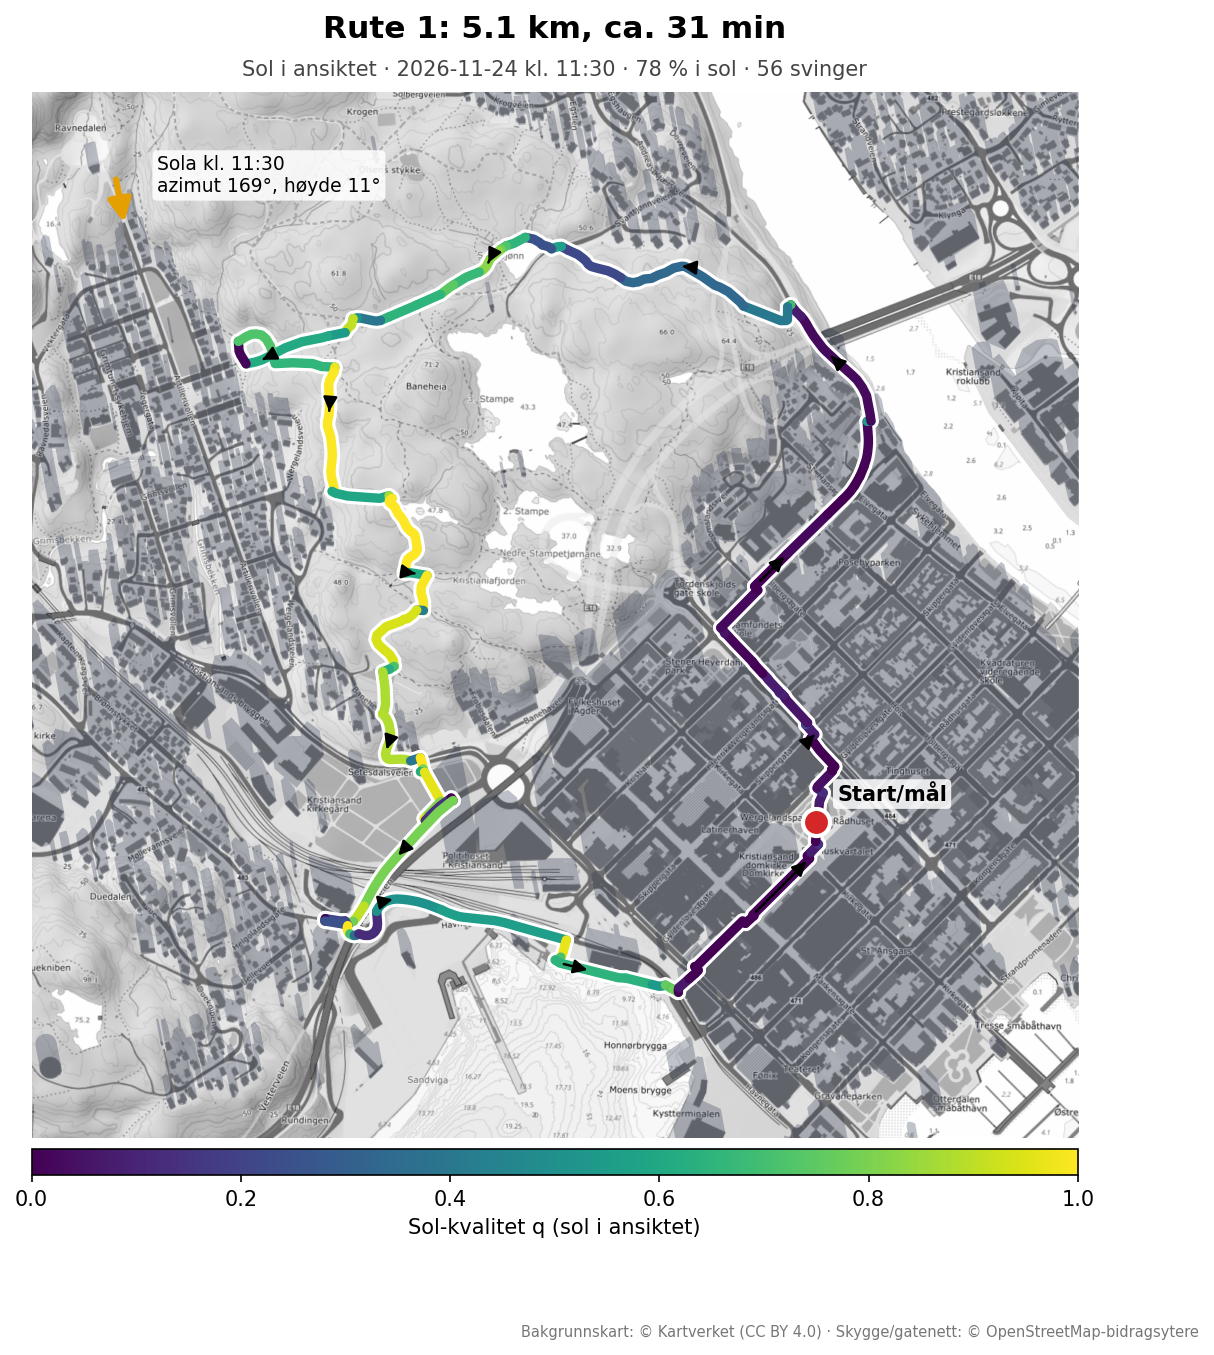

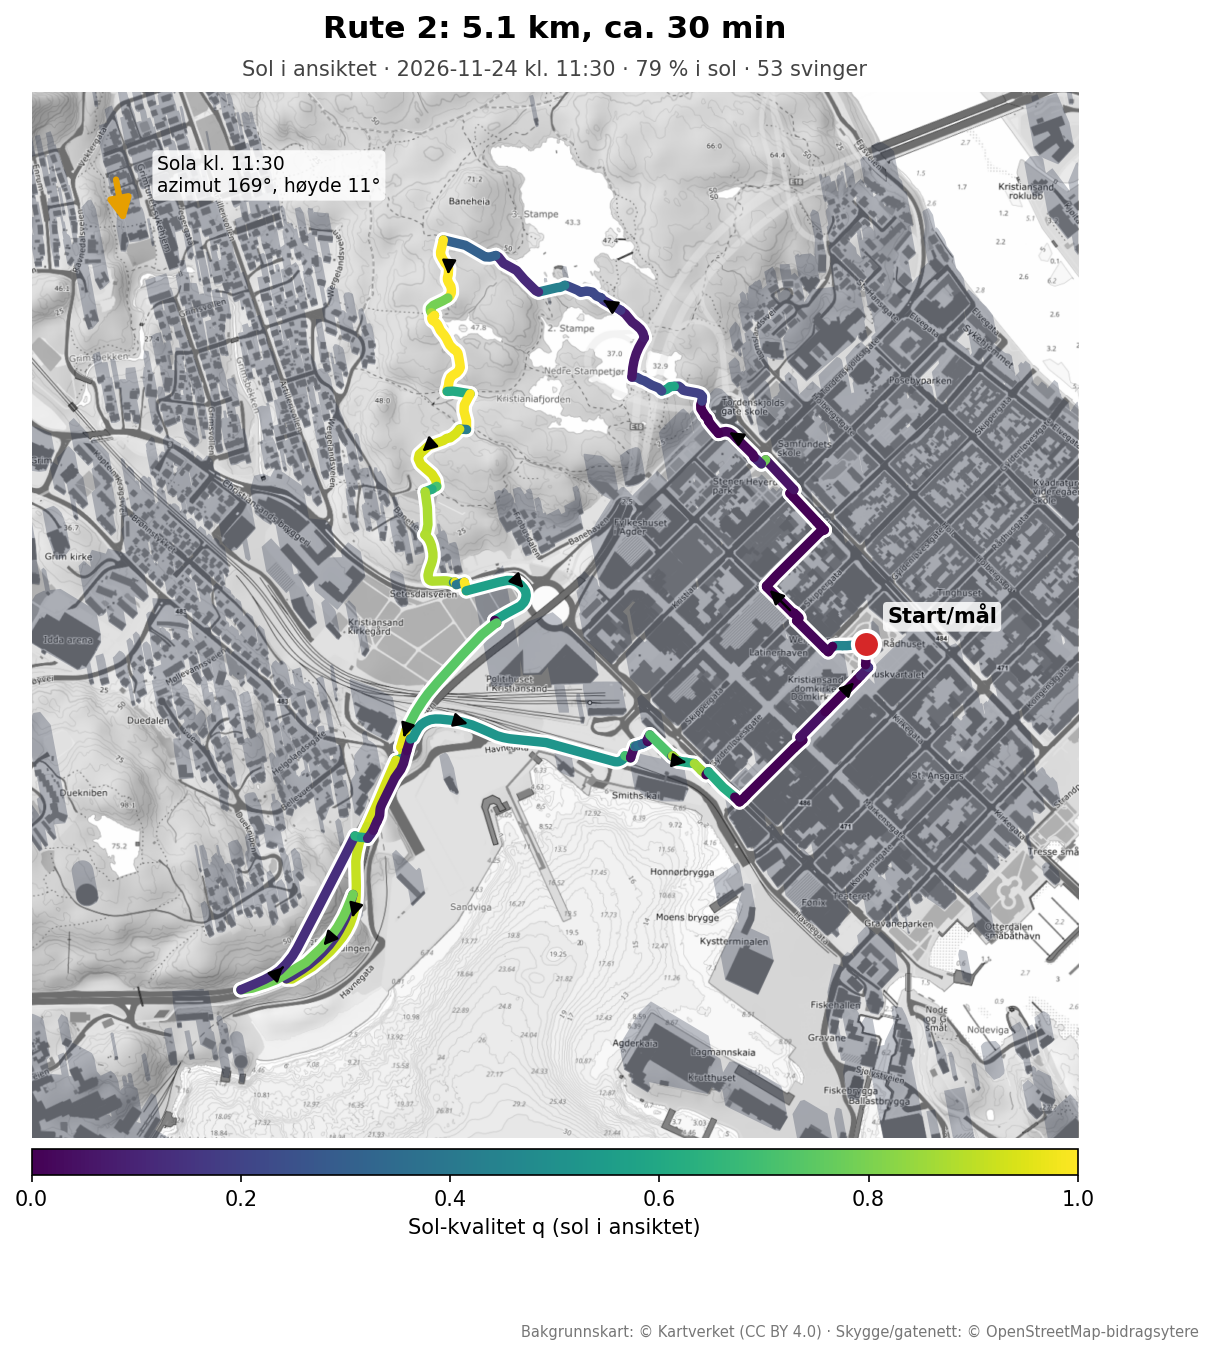

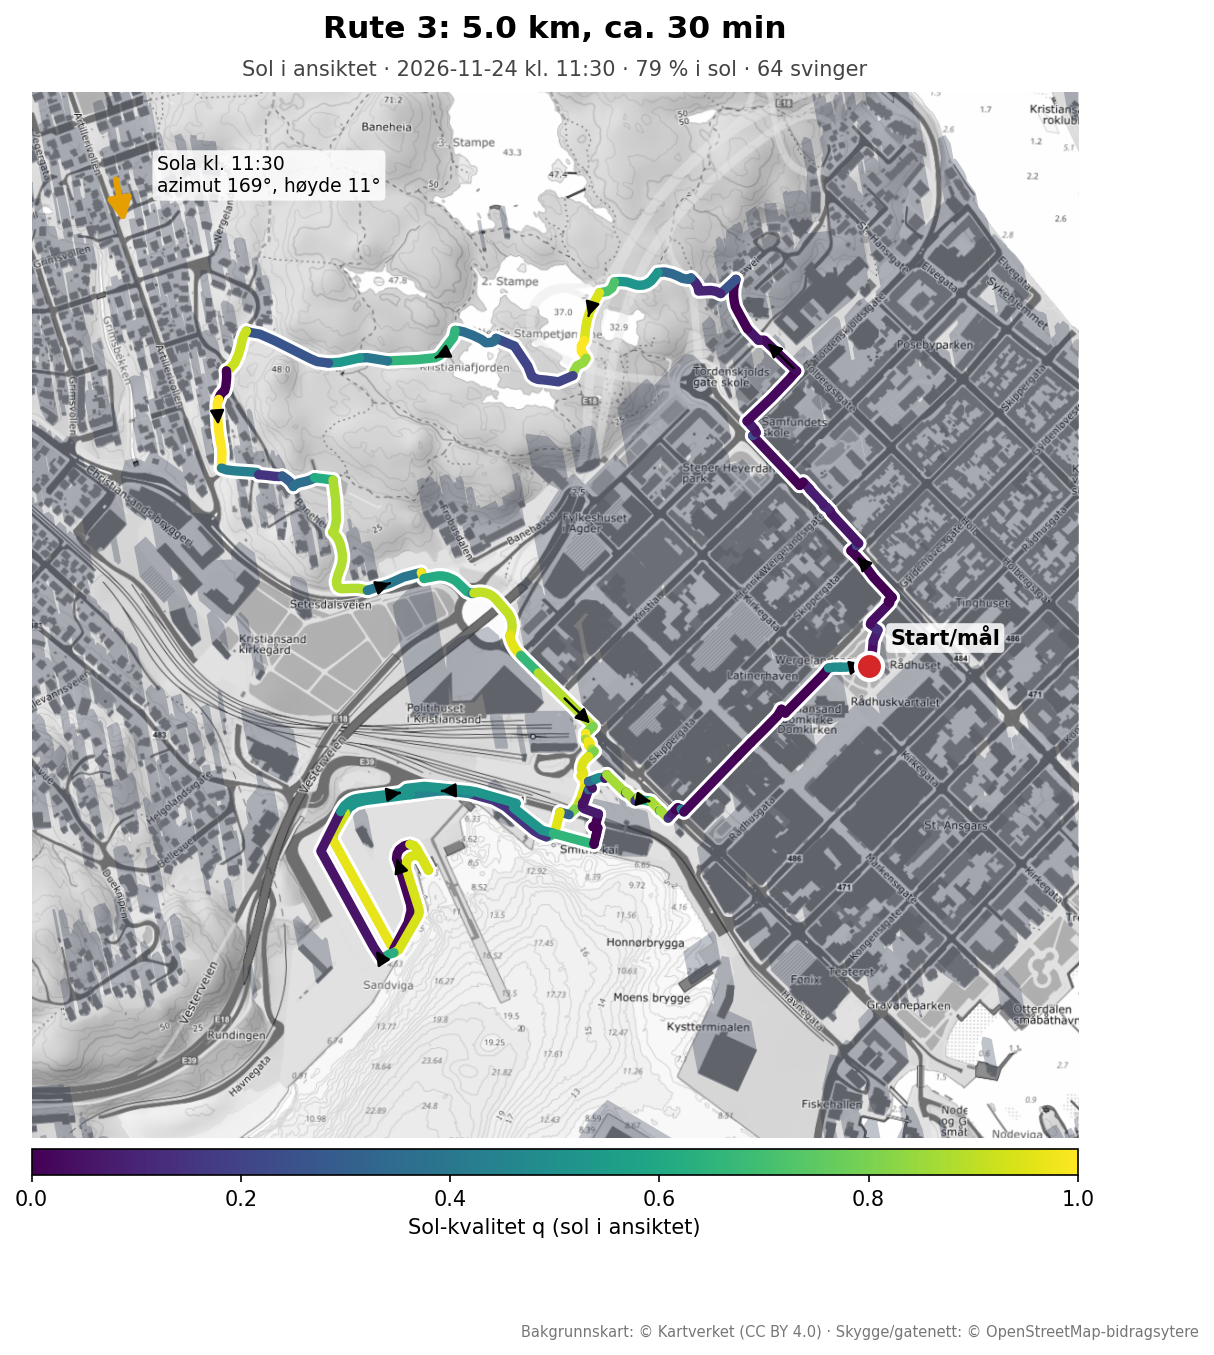

Lagret 3 kart i kart/


In [15]:
from pathlib import Path

UT_MAPPE = Path("kart")
UT_MAPPE.mkdir(exist_ok=True)
for rang, r in enumerate(valgt, start=1):
    fig = tegn_kart(r, rang)
    fig.savefig(UT_MAPPE / f"sunrun_{KRITERIUM}_{rang}.png", dpi=200, bbox_inches="tight",
                facecolor="white")
    plt.show()
    plt.close(fig)
print(f"Lagret {len(valgt)} kart i {UT_MAPPE}/")

## 11. Eksport av alle ruter til GeoJSON

Alle **gyldige** kandidatruter (ikke bare topp 3) eksporteres som én `FeatureCollection` med `LineString`-geometri i WGS84 (EPSG:4326), sortert etter sol-kvalitet. `valgt = true` markerer de rutene som er vist på kartene over.

In [16]:
import json

valgt_ids = {id(r) for r in valgt}
features = []
linjer_p = [shapely.LineString(np.vstack(rute_segmenter(r))) for r in resultater]
linjer_ll = gpd.GeoSeries(linjer_p, crs=CRS).to_crs(4326)
for rang, (r, linje) in enumerate(zip(resultater, linjer_ll), start=1):
    features.append({
        "type": "Feature",
        "geometry": shapely.geometry.mapping(shapely.set_precision(linje, 1e-6)),
        "properties": {
            "rang": rang,
            "valgt": id(r) in valgt_ids,
            "kriterium": KRITERIUM,
            "dato": DATO,
            "klokkeslett": KLOKKESLETT,
            "lengde_km": round(r["lengde"] / 1000, 3),
            "tid_min": round(r["lengde"] * MIN_PER_METER, 1),
            "sol_kvalitet": round(r["score"], 4),
            "andel_sol": round(r["sol_pct"], 4),
            "andel_sol_ansikt": round(r["ansikt_pct"], 4),
            "andel_sol_rygg": round(r["rygg_pct"], 4),
            "svinger": r["svinger"],
        },
    })

geojson_fil = UT_MAPPE / f"sunrun_{KRITERIUM}_ruter.geojson"
geojson_fil.write_text(json.dumps({"type": "FeatureCollection", "features": features},
                                  ensure_ascii=False), encoding="utf-8")
print(f"Eksporterte {len(features)} ruter til {geojson_fil}")

Eksporterte 50 ruter til kart/sunrun_ansikt_ruter.geojson


## 12. Begrensninger og veien videre

- **Skygge:** kun bygninger. Trær, terreng og lav sol bak åser ignoreres. Konvekst skrog overestimerer skygge for L-formede bygg.
- **Bygningshøyde:** mangler ofte i OSM, og standardhøyden (8 m) gir systematiske feil.
- **Retning:** `bearing` er korden mellom endenodene. Krumme kanter får dermed litt unøyaktig retning.
- **Tempo:** konstant, uten hensyn til stigning, trapper eller underlag.
- **Heuristikk:** ingen optimalitetsgaranti (se kap. 2). Mulige forbedringer: lokalsøk (2-opt / bytt delstrekninger), flere mellompunkter, eller eksakt branch-and-cut på et delgraf-utsnitt for å måle gapet til heuristikken.
- **Eksport:** GPX er ikke implementert.